# Figure 1c Local methods comparison


Six Eigengene rates at residual correlation `rho = 0.1` and their displayed intervals were changed synthetically. The RDS retains their original rates and intervals for inspection; it deliberately omits rejection counts and standard errors because they do not correspond to the synthetic bars. All other plotted values are unchanged from the source TSV. This notebook reads only the plot-ready RDS and draws the preview.

In [ ]:
suppressPackageStartupMessages(library(ggplot2))
x <- readRDS("data/Figure_1c_local_comparison.rds")
stopifnot(identical(x$scientific_use, FALSE),
          nrow(x$plot_data) == 72L, nrow(x$synthetic_rows) == 6L,
          all(x$synthetic_rows$rho == 0.1),
          all(x$synthetic_rows$rate != x$synthetic_rows$original_rate))
print(x$synthetic_rows[, c("rho", "s", "sign_mode",
                           "rate", "original_rate")], row.names = FALSE)

Warning message:
"package 'ggplot2' was built under R version 4.4.3"


 rho      s sign_mode      rate original_rate
 0.1 0.0025  positive 0.7150780     0.8661667
 0.1 0.0040  positive 0.8674242     0.9221667
 0.1 0.0100  positive 0.9774040     0.9535000
 0.1 0.0025  balanced 0.7424625     0.8851667
 0.1 0.0040  balanced 0.8736051     0.9226667
 0.1 0.0100  balanced 0.9821610     0.9533333


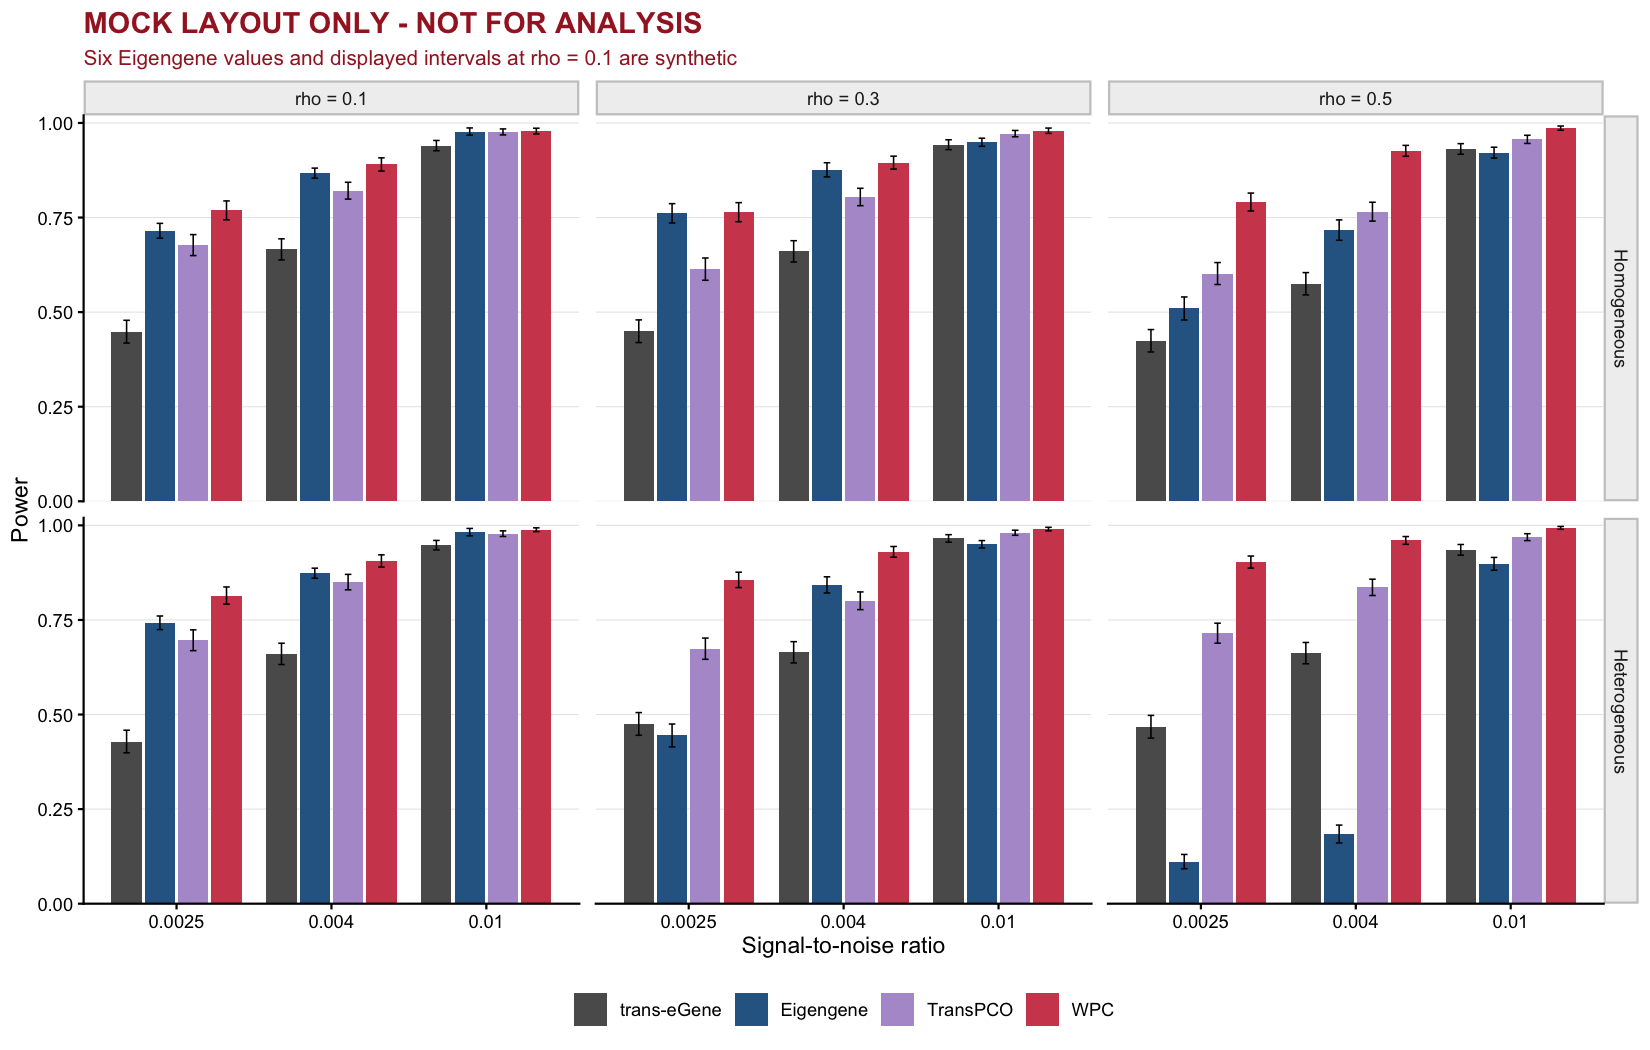

In [ ]:
p <- x$plot_data
p$method_label <- factor(p$method_label,
  levels = c("trans-eGene", "Eigengene", "TransPCO (cor(Y))", "WPC"),
  labels = c("trans-eGene", "Eigengene", "TransPCO", "TransMap-local"))
p$snr <- factor(p$s, levels = c(0.0025, 0.004, 0.01),
                labels = c("0.0025", "0.004", "0.01"))
p$rho_label <- factor(p$rho, levels = c(0.1, 0.3, 0.5),
                      labels = c("rho = 0.1", "rho = 0.3", "rho = 0.5"))
p$effect_mode <- factor(p$sign_mode, levels = c("positive", "balanced"),
                        labels = c("Homogeneous", "Heterogeneous"))
g <- ggplot(p, aes(x = snr, y = rate, fill = method_label)) +
  geom_col(position = position_dodge(width = 0.86), width = 0.78) +
  geom_errorbar(aes(ymin = ci_lower, ymax = ci_upper),
                position = position_dodge(width = 0.86),
                width = 0.17, linewidth = 0.35) +
  facet_grid(effect_mode ~ rho_label) +
  scale_fill_manual(values = c("trans-eGene" = "#5B5B5B",
                               "Eigengene" = "#2C6693",
                               "TransPCO" = "#B29BD0",
                               "TransMap-local" = "#D04B5C"), name = NULL) +
  scale_y_continuous(limits = c(0, 1), breaks = seq(0, 1, 0.25),
                     expand = expansion(mult = c(0, 0.02))) +
  labs(x = "Signal-to-noise ratio", y = "Power"
  theme_classic(base_size = 11) +
  theme(plot.title = element_text(color = "#A4232A", face = "bold", size = 14),
        plot.subtitle = element_text(color = "#A4232A", size = 10),
        strip.background = element_rect(fill = "#F0F0F0", color = "#C9C9C9"),
        strip.text = element_text(color = "#222222"),
        panel.grid.major.y = element_line(color = "#E8E8E8", linewidth = 0.25),
        legend.position = "bottom",
        panel.spacing = unit(0.55, "lines"))
options(repr.plot.width = 11, repr.plot.height = 7, repr.plot.res = 150)
print(g)